In [225]:
import requests
import pandas as pd
import pyod
from pyod.models.pca import PCA
from pyod.models.knn import KNN
from pyod.models.ocsvm import OCSVM
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot 

Задание 1

In [162]:
HEADERS = {'User-Agent': 'Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 ' '(KHTML, like Gecko) Chrome/126.0 Safari/537.36', 'Accept': 'application/json'}

vacancies = []
for page in range(20):

    params = {'text': 'Разработчик', 'search_field': 'name', 'only_with_salary': 'true', 'enable_snippets': 'true', 'items_on_page': 100, 'page': page}
    response = requests.get('https://hh.ru/shards/vacancy/search', params=params, headers=HEADERS)

    vacancies.extend(response.json()['vacancySearchResult']['vacancies'])



Задание 2

In [201]:
cols = 'id, name, area.name, salary.from, salary.to, salary.gross, salary.currency, snippet.requirements, experience.name.'.split(', ')

df = pd.DataFrame(columns=cols)

for v in vacancies:
    c = v['compensation']
    df.loc[len(df)] = [v['vacancyId'], v['name'], v['area']['name'], c.get('from'), c.get('to'), c.get('gross'), c.get('currencyCode'), (v.get('snippet') or {}).get('req'), v['workExperience']]

    
df

,id,name,area.name,salary.from,salary.to,salary.gross,salary.currency,snippet.requirements,experience.name.
0,138322208,Middle Fullstack разработчик,Казань,150000,180000,False,RUR,"Кросс-браузерная адаптивная верстка HTML, CSS....",between3And6
1,138663996,Middle Fullstack JavaScript Developer,Ташкент,1500,2000,False,USD,Коммерческий опыт работы Fullstack / Backend /...,between1And3
2,138057941,Разработчик Cs-Cart,Ташкент,6000000,10000000,True,UZS,Опыт разработки на CS‑Cart или Multi‑Vendor от...,between1And3
3,138294911,Fullstack разработчик PHP / Node + Vue / Nuxt ...,Новосибирск,200000,200000,False,RUR,Основной backend сейчас — монолит на PHP / Sym...,between3And6
4,138792398,Frontend-разработчик (Разработка игр),Ярославль,50000,None,False,RUR,Базовые знания в программировании. Высшее проф...,noExperience
...,...,...,...,...,...,...,...,...,...
1996,135279103,Инженер-программист токарных станков с ЧПУ,Заречный (Пензенская область),80000,100000,False,RUR,Умение читать чертежи. Умение работы с техноло...,between1And3
1997,138279042,Инженер-программист АСУТП SystemeHD,Москва,140000,None,False,RUR,Просьба не откликаться на вакансию без аналоги...,between3And6
1998,137193054,Оператор-программист ЧПУ (фрезеровщик),Азов,100000,None,False,RUR,Умения программировать станок VMC 850 (Fanuc)....,between1And3
1999,138288479,Рендер программист / render engineer (Direct3D...,Санкт-Петербург,150000,220000,False,RUR,можешь закодить point и spot lights с нуля от ...,between3And6


In [176]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2001 entries, 0 to 2000
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   id                    2001 non-null   int64 
 1   name                  2001 non-null   object
 2   area.name             2001 non-null   object
 3   salary.from           1781 non-null   object
 4   salary,to             1025 non-null   object
 5   salary.gross          2001 non-null   bool  
 6   salary.currency       2001 non-null   object
 7   snippet.requirements  1972 non-null   object
 8   experience.name.      2001 non-null   object
dtypes: bool(1), int64(1), object(7)
memory usage: 142.6+ KB


Задание 3

In [207]:
mask = df['salary.from'].notna() & df['salary.to'].notna()  
df.loc[mask, 'clean_sal'] = (df.loc[mask, 'salary.from'] + df.loc[mask, 'salary.to']) / 2


In [211]:
df['salary.currency'].unique()

array(['RUR', 'USD', 'UZS', 'BYR', 'KZT', 'KGS', 'EUR'], dtype=object)

In [209]:
to_rub = {
    'RUR': 1,
    'USD': 81.12,
    'EUR': 91.13, 
    'BYR': 27.46,     # белорусский рубль
    'KZT': 0.1808,    # тенге
    'KGS': 0.9277,    # сом
    'UZS': 0.00678,   # сум
}

df['clean_sal'] = df['clean_sal'] * df['salary.currency'].map(to_rub)


In [215]:
df

,id,name,area.name,salary.from,salary.to,salary.gross,salary.currency,snippet.requirements,experience.name.,clean_sal
0,138322208,Middle Fullstack разработчик,Казань,150000,180000,False,RUR,"Кросс-браузерная адаптивная верстка HTML, CSS....",between3And6,165000.0
1,138663996,Middle Fullstack JavaScript Developer,Ташкент,1500,2000,False,USD,Коммерческий опыт работы Fullstack / Backend /...,between1And3,141960.0
2,138057941,Разработчик Cs-Cart,Ташкент,6000000,10000000,True,UZS,Опыт разработки на CS‑Cart или Multi‑Vendor от...,between1And3,54240.0
3,138294911,Fullstack разработчик PHP / Node + Vue / Nuxt ...,Новосибирск,200000,200000,False,RUR,Основной backend сейчас — монолит на PHP / Sym...,between3And6,200000.0
4,138792398,Frontend-разработчик (Разработка игр),Ярославль,50000,None,False,RUR,Базовые знания в программировании. Высшее проф...,noExperience,NaN
...,...,...,...,...,...,...,...,...,...,...
1996,135279103,Инженер-программист токарных станков с ЧПУ,Заречный (Пензенская область),80000,100000,False,RUR,Умение читать чертежи. Умение работы с техноло...,between1And3,90000.0
1997,138279042,Инженер-программист АСУТП SystemeHD,Москва,140000,None,False,RUR,Просьба не откликаться на вакансию без аналоги...,between3And6,NaN
1998,137193054,Оператор-программист ЧПУ (фрезеровщик),Азов,100000,None,False,RUR,Умения программировать станок VMC 850 (Fanuc)....,between1And3,NaN
1999,138288479,Рендер программист / render engineer (Direct3D...,Санкт-Петербург,150000,220000,False,RUR,можешь закодить point и spot lights с нуля от ...,between3And6,185000.0


Задание 4

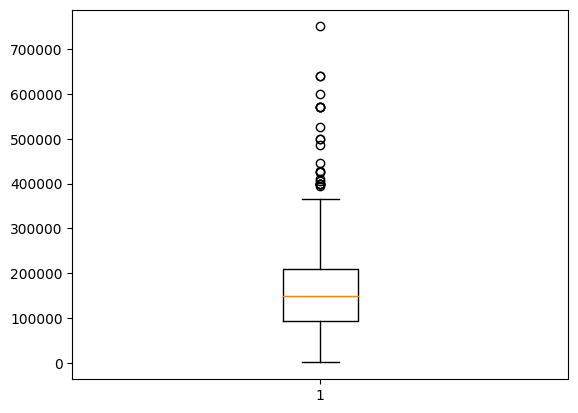

In [219]:
import matplotlib.pyplot as plt

plt.boxplot(df['clean_sal'].dropna())
plt.show()

Задание 5 и 6

In [231]:
X = df[['clean_sal']].dropna()

X_scaled = StandardScaler().fit_transform(X)

models = {
    'anomaly1': PCA(contamination=0.05, random_state=42),
    'anomaly2': KNN(contamination=0.05),
    'anomaly3': OCSVM(contamination=0.05),
}

for col, model in models.items():
      model.fit(X_scaled)
      df.loc[X.index, col] = model.labels_      


df['anomaly'] = df[['anomaly1', 'anomaly2', 'anomaly3']].mean(axis=1).round()

In [233]:
mask = df['anomaly'] == 1

In [242]:
df.loc[mask, :]

,id,name,area.name,salary.from,salary.to,salary.gross,salary.currency,snippet.requirements,experience.name.,clean_sal,anomaly1,anomaly2,anomaly3,anomaly
12,118990654,Разработчик,Санкт-Петербург,512000,768000,True,RUR,имели твёрдые фундаментальные знания математик...,between3And6,640000.0,1.0,1.0,1.0,1.0
22,134881609,Разработчик (Backend),Санкт-Петербург,512000,768000,True,RUR,имели твёрдые фундаментальные знания математик...,between3And6,640000.0,1.0,1.0,1.0,1.0
58,136682500,Программист CRM,Санкт-Петербург,320000,350000,True,RUR,...Oracle Siebel и/или др.). Участие в проекта...,between3And6,335000.0,0.0,1.0,1.0,1.0
73,138790412,Ведущий разработчик-программист 1С,Баку,500,2500,True,RUR,Опыт работы с хранилищами и расширениями 1С. Т...,between1And3,1500.0,1.0,1.0,1.0,1.0
87,138515561,Ведущий разработчик встроенного ПО (team lead),Зеленоград,400000,400000,False,RUR,Опыт документирования ПО. Опыт постановки зада...,between3And6,400000.0,0.0,1.0,1.0,1.0
305,136825709,Программист-senior на Cobol,Курчатов (Казахстан),50000,60000,True,KZT,Опыт в разработке приложений на языке COBOL бо...,between3And6,9944.0,1.0,1.0,0.0,1.0
350,136083468,"Senior backend developer (PHP, Symfony) в Fintech",Москва,400000,600000,False,RUR,Опыт командной разработки от 5-х лет. Хороший ...,between3And6,500000.0,1.0,1.0,1.0,1.0
375,138230953,Ведущий разработчик (Tech Lead) платформы ИИ-а...,Москва,450000,550000,True,RUR,"Ядро. REST API, очередь запусков на PostgreSQL...",between3And6,500000.0,1.0,1.0,1.0,1.0
396,138669225,Java-разработчик,Москва,300000,400000,False,RUR,Разработка нового продукта вместе с архитектор...,between3And6,350000.0,0.0,1.0,1.0,1.0
604,138413511,AI-first разработчик,Москва,5000,6000,True,USD,Есть опыт работы с данными или ML в любом виде...,moreThan6,446160.0,0.0,1.0,1.0,1.0


Задача 7